# Intuitive Guide: Vector & Quantum Observer Geometries
## Exploring Network Holonomy, Unit Balls, and the Bloch Sphere
**Paper Reference:** `GS-003` (`vector_and_quantum_observer_geometries`)  
**AuthorityEffect:** None.  

---

## 1. The Observer Calibration Problem: Gauges and 1-Cycles
Imagine a network of distributed quantum or classical observers stationed at vertices $V = \{0, 1, 2\}$ of a triangular circuit.

- Each observer $u$ maintains a local reference frame or gauge potential $\phi(u)$.
- Directed communication channels along edges $e = (u, v)$ register measured signal differences $\delta_e$.
- If observers recalibrate their local reference frames, the edge measurement transforms by the coboundary:
  $$(d_0 \phi)(u, v) = \phi(v) - \phi(u)$$
- The fundamental question of **gauge relativity** is:
  > *Can observers mutually recalibrate their sensors to explain away all measured edge signals, or is there an unavoidable topological obstruction?*

If the sum of signals around the cycle (the **circulation** $c = \sum_{e \in C} \delta_e$) is non-zero, no choice of vertex calibrations can eliminate it. The minimal residual error depends entirely on the **geometry of the observer's ruler** (the norm).

In [1]:
import sys
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def _boot_libs(*names):
    # Robustly resolve and import library directories regardless of CWD.
    cwd = Path.cwd().resolve()
    search_dirs = [cwd] + list(cwd.parents)
    for ancestor in [cwd] + list(cwd.parents):
        cand = ancestor / "coda_atlas" / "papers" / "projection_obstruction" / "vector_and_quantum_observer_geometries"
        if cand.exists():
            search_dirs.insert(0, cand)
            break
    for name in names:
        for base in search_dirs:
            p = (base / name).resolve()
            if p.is_dir() and p.exists():
                if str(p) not in sys.path:
                    sys.path.insert(0, str(p))
                return str(p)
            sub = base / "vector_and_quantum_observer_geometries" / name
            if sub.is_dir() and sub.exists():
                sub_res = sub.resolve()
                if str(sub_res) not in sys.path:
                    sys.path.insert(0, str(sub_res))
                return str(sub_res)
    raise FileNotFoundError(f"none of {names} found from {cwd}")

code_dir = _boot_libs("code")

from cochain_complex import GraphComplex, Cochain
from classical_geometry import ClassicalQuotientSolver
from quantum_geometry import HermitianOperator, QuantumQuotientSolver
from cptp_channels import KrausChannel, CochainMorphism
from demonstrations import (
    demo_classical_triangle_separation,
    demo_quantum_triangle_uniform_z,
    demo_bloch_isometry_vs_qutrit_crosspolytope,
    demo_cptp_quotient_monotonicity,
)
print("[+] GS-003 Intuitive Environment Successfully Initialized!")
print(f"    Code Kernel Path: {code_dir}")

[+] GS-003 Intuitive Environment Successfully Initialized!
    Code Kernel Path: C:\Users\a343o\source\repos\CODA\coda_atlas\papers\projection_obstruction\vector_and_quantum_observer_geometries\code


## 2. The Geometry of Rulers: Unit Balls Compared
When an observer quantifies a 2D error vector $\vec{v} = (x, y)$, how does the chosen geometry affect the perceived magnitude?

1. **Taxicab Metric ($\ell^1$):** $\|(x, y)\|_1 = |x| + |y|$. Independent coordinate channels; the unit ball is a diamond.
2. **Euclidean Metric ($\ell^2$):** $\|(x, y)\|_2 = \sqrt{x^2 + y^2}$. Rotationally invariant; the unit ball is a circle.
3. **Chebyshev Metric ($\ell^\infty$):** $\|(x, y)\|_\infty = \max(|x|, |y|)$. Worst-case coordinate error; the unit ball is a square.
4. **Quantum Trace Distance ($j_Q$):** For a single qubit, any traceless Hermitian matrix is $X = v_x \sigma_x + v_y \sigma_y + v_z \sigma_z$. Its normalized trace distance is $j_Q(X) = \frac{1}{2}\|X\|_1 = \|\vec{v}\|_2$, forming the **Bloch Sphere**.

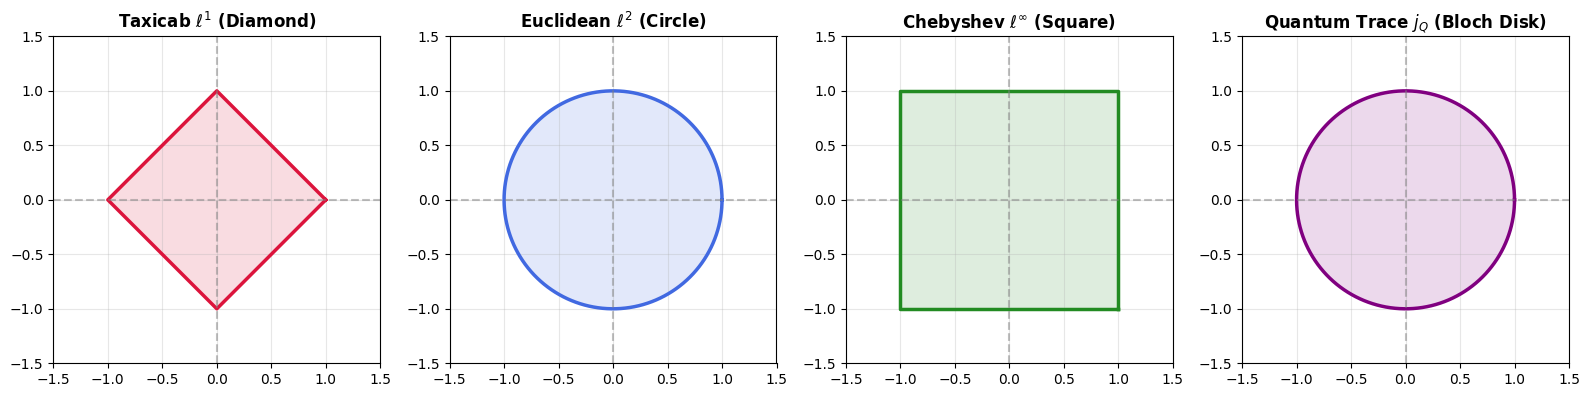

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
theta = np.linspace(0, 2*np.pi, 600)

# 1. Taxicab l1
ax = axes[0]
diamond_x = [1, 0, -1, 0, 1]
diamond_y = [0, 1, 0, -1, 0]
ax.plot(diamond_x, diamond_y, 'crimson', lw=2.5)
ax.fill(diamond_x, diamond_y, 'crimson', alpha=0.15)
ax.set_title(r'Taxicab $\ell^1$ (Diamond)', fontsize=12, fontweight='bold')

# 2. Euclidean l2
ax = axes[1]
ax.plot(np.cos(theta), np.sin(theta), 'royalblue', lw=2.5)
ax.fill(np.cos(theta), np.sin(theta), 'royalblue', alpha=0.15)
ax.set_title(r'Euclidean $\ell^2$ (Circle)', fontsize=12, fontweight='bold')

# 3. Chebyshev l_inf
ax = axes[2]
square_x = [1, 1, -1, -1, 1]
square_y = [-1, 1, 1, -1, -1]
ax.plot(square_x, square_y, 'forestgreen', lw=2.5)
ax.fill(square_x, square_y, 'forestgreen', alpha=0.15)
ax.set_title(r'Chebyshev $\ell^\infty$ (Square)', fontsize=12, fontweight='bold')

# 4. Quantum Trace Ball Slice (Bloch Disk)
ax = axes[3]
ax.plot(np.cos(theta), np.sin(theta), 'purple', lw=2.5)
ax.fill(np.cos(theta), np.sin(theta), 'purple', alpha=0.15)
ax.set_title(r'Quantum Trace $j_Q$ (Bloch Disk)', fontsize=12, fontweight='bold')

for ax in axes:
    ax.axhline(0, color='gray', ls='--', alpha=0.5)
    ax.axvline(0, color='gray', ls='--', alpha=0.5)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. The Triangle Loop Anomaly: Classical Separation
Consider a 3-cycle triangle $V = \{0, 1, 2\}$ with edges $(0, 1), (1, 2), (2, 0)$ carrying signals:
$$\omega_{01} = (1, 0), \quad \omega_{12} = (0, 1), \quad \omega_{20} = (0, 0)$$
The total circulation around the triangle is:
$$c = \omega_{01} + \omega_{12} + \omega_{20} = (1, 1)$$

When observers choose potentials $\phi(0), \phi(1), \phi(2) \in \mathbb{R}^2$, how small can they make the total network error?
- **Taxicab Observer ($\ell^1$):** Minimal error is $\Phi_{1,1} = 2.0$.
- **Euclidean Observer ($\ell^2$):** Minimal error is $\Phi_{2,1} = \sqrt{2} \approx 1.41421356$.
- **Separation Ratio:** $\Phi_{1,1} / \Phi_{2,1} = 2.0 / \sqrt{2} = \sqrt{2} \approx 1.414$!

Circulation Vector c: [1.0, 1.0]
Taxicab Minimal Obstruction Phi_{1,1}: 2.000000 (Dual: 2.000000, Gap: 0.0e+00)
Euclidean Minimal Obstruction Phi_{2,1}: 1.414214 (Dual: 1.414214, Gap: 0.0e+00)
Chebyshev Minimal Obstruction Phi_{inf,1}: 1.000000 (Gap: 0.0e+00)
Separation Ratio Phi_{1,1} / Phi_{2,1}: 1.414214
Theoretical sqrt(2): 1.414214


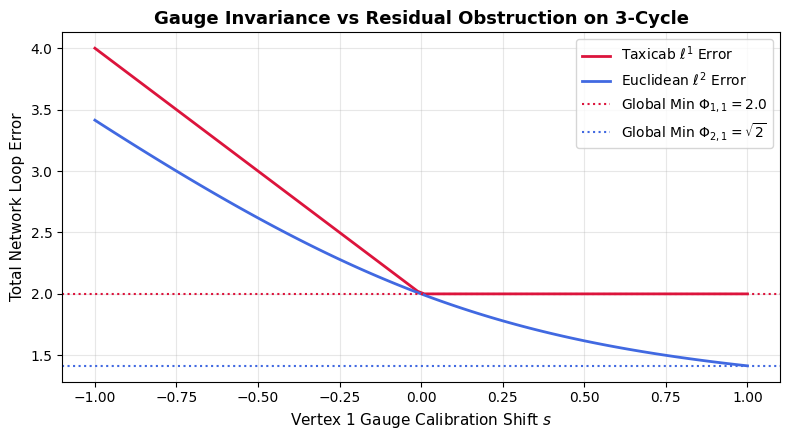

In [3]:
demo1 = demo_classical_triangle_separation()
print(f"Circulation Vector c: {demo1['circulation']}")
print(f"Taxicab Minimal Obstruction Phi_{{1,1}}: {demo1['phi_1_1_primal']:.6f} (Dual: {demo1['phi_1_1_dual']:.6f}, Gap: {demo1['phi_1_1_gap']:.1e})")
print(f"Euclidean Minimal Obstruction Phi_{{2,1}}: {demo1['phi_2_1_primal']:.6f} (Dual: {demo1['phi_2_1_dual']:.6f}, Gap: {demo1['phi_2_1_gap']:.1e})")
print(f"Chebyshev Minimal Obstruction Phi_{{inf,1}}: {demo1['phi_inf_1_primal']:.6f} (Gap: {demo1['phi_inf_1_gap']:.1e})")
print(f"Separation Ratio Phi_{{1,1}} / Phi_{{2,1}}: {demo1['separation_ratio_l1_over_l2']:.6f}")
print(f"Theoretical sqrt(2): {demo1['theoretical_sqrt2']:.6f}")

# Visualizing error redistribution under gauge shift phi
shifts = np.linspace(-1.0, 1.0, 100)
errs_l1 = []
errs_l2 = []
for s in shifts:
    e01 = np.array([1.0 - s, 0.0])
    e12 = np.array([s, 1.0])
    e20 = np.array([0.0, 0.0])
    errs_l1.append(np.sum(np.abs(e01)) + np.sum(np.abs(e12)) + np.sum(np.abs(e20)))
    errs_l2.append(np.linalg.norm(e01) + np.linalg.norm(e12) + np.linalg.norm(e20))

plt.figure(figsize=(8, 4.5))
plt.plot(shifts, errs_l1, 'crimson', lw=2, label=r'Taxicab $\ell^1$ Error')
plt.plot(shifts, errs_l2, 'royalblue', lw=2, label=r'Euclidean $\ell^2$ Error')
plt.axhline(demo1['phi_1_1_primal'], color='crimson', ls=':', label=r'Global Min $\Phi_{1,1} = 2.0$')
plt.axhline(demo1['phi_2_1_primal'], color='royalblue', ls=':', label=r'Global Min $\Phi_{2,1} = \sqrt{2}$')
plt.xlabel(r'Vertex 1 Gauge Calibration Shift $s$', fontsize=11)
plt.ylabel('Total Network Loop Error', fontsize=11)
plt.title('Gauge Invariance vs Residual Obstruction on 3-Cycle', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 4. Quantum Observer Geometry & The Bloch Sphere
In quantum mechanics, a 2-level quantum state (qubit) is described by a $2 \times 2$ density matrix $\rho$.
Any difference between states is a traceless Hermitian operator:
$$X = \vec{v} \cdot \vec{\sigma} = v_x \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} + v_y \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} + v_z \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$

The normalized quantum trace distance is:
$$j_Q(X) = \frac{1}{2} \|X\|_1 = \frac{1}{2} \mathrm{Tr}\left(\sqrt{X^\dagger X}\right)$$
For any qubit operator $X = \vec{v} \cdot \vec{\sigma}$, its eigenvalues are $\pm \|\vec{v}\|_2$, so:
$$j_Q(X) = \|\vec{v}\|_2$$
**Theorem (Bloch Isometry):** On single qubits ($d=2$), quantum trace geometry is *isometrically identical* to 3D Euclidean geometry! Parallelogram equality holds with machine precision.

Qubit Bloch Isometry Difference: 0.00e+00
Qubit Parallelogram Law Error:    3.55e-15
Qubit is Euclidean:               True
Qutrit (d=3) Parallelogram LHS:   16.0
Qutrit (d=3) Parallelogram RHS:   20.0
Qutrit Discrepancy:               4.0 (Non-Euclidean: True)


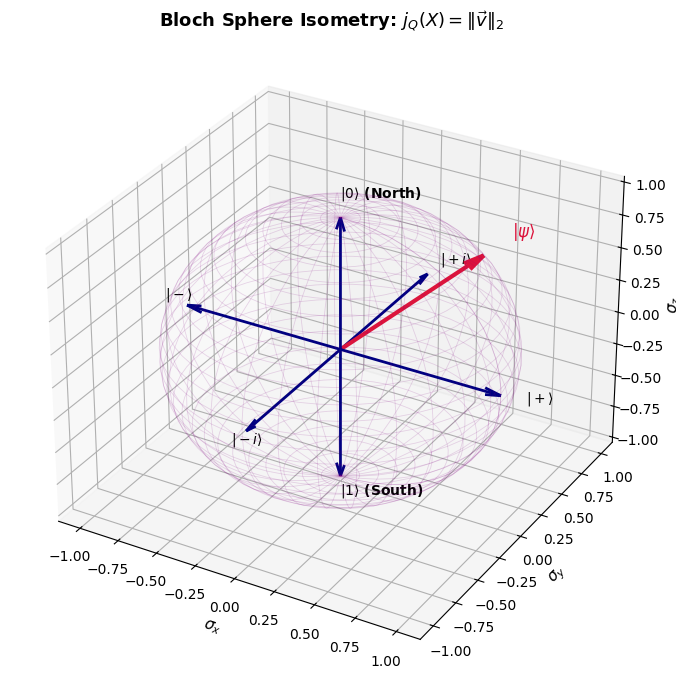

In [4]:
demo3 = demo_bloch_isometry_vs_qutrit_crosspolytope()
print(f"Qubit Bloch Isometry Difference: {demo3['qubit_bloch_isometry_diff']:.2e}")
print(f"Qubit Parallelogram Law Error:    {demo3['qubit_parallelogram_err']:.2e}")
print(f"Qubit is Euclidean:               {demo3['qubit_is_euclidean']}")
print(f"Qutrit (d=3) Parallelogram LHS:   {demo3['qutrit_parallelogram_lhs']:.1f}")
print(f"Qutrit (d=3) Parallelogram RHS:   {demo3['qutrit_parallelogram_rhs']:.1f}")
print(f"Qutrit Discrepancy:               {demo3['qutrit_parallelogram_discrepancy']:.1f} (Non-Euclidean: {demo3['qutrit_is_non_euclidean']})")

# 3D Visualization of the Bloch Sphere
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')

u = np.linspace(0, 2 * np.pi, 60)
v = np.linspace(0, np.pi, 30)
x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_wireframe(x, y, z, color='purple', alpha=0.15, lw=0.6)

# Key state vectors on the sphere
states = {
    r'$|0\rangle$ (North)': [0, 0, 1],
    r'$|1\rangle$ (South)': [0, 0, -1],
    r'$|+\rangle$': [1, 0, 0],
    r'$|-\rangle$': [-1, 0, 0],
    r'$|+i\rangle$': [0, 1, 0],
    r'$|-i\rangle$': [0, -1, 0],
}
for name, vec in states.items():
    ax.quiver(0, 0, 0, vec[0], vec[1], vec[2], color='navy', lw=2, arrow_length_ratio=0.1)
    ax.text(vec[0]*1.15, vec[1]*1.15, vec[2]*1.15, name, fontsize=10, fontweight='bold')

# Sample state vector
psi_vec = [1/np.sqrt(3), 1/np.sqrt(3), 1/np.sqrt(3)]
ax.quiver(0, 0, 0, psi_vec[0], psi_vec[1], psi_vec[2], color='crimson', lw=3, arrow_length_ratio=0.12)
ax.text(psi_vec[0]*1.2, psi_vec[1]*1.2, psi_vec[2]*1.2, r'$|\psi\rangle$', color='crimson', fontsize=12, fontweight='bold')

ax.set_xlabel(r'$\sigma_x$', fontsize=11)
ax.set_ylabel(r'$\sigma_y$', fontsize=11)
ax.set_zlabel(r'$\sigma_z$', fontsize=11)
ax.set_title(r'Bloch Sphere Isometry: $j_Q(X) = \|\vec{v}\|_2$', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Environmental Decoherence: CPTP Quotient Monotonicity
When a quantum network is exposed to environmental noise, quantum operations are modeled by **Completely Positive Trace-Preserving (CPTP)** channels $\mathcal{E}$.

Under a valid cochain morphism where local operations commute with network boundaries ($\Lambda^1 d_0 = d_0' \Lambda^0$):
$$\Phi_Q'([\Lambda^1 \delta]) \le \Phi_Q([\delta])$$

Physical meaning:
- **Noise cannot synthesize topological obstruction out of thin air.**
- Under depolarizing noise, the obstruction smoothly contracts towards $0$.
- Under unitary operations (reversible rotations), the obstruction is strictly conserved!

Baseline Quantum Obstruction Phi_Q: 1.5000
Depolarizing Noise (p=0.4):          Phi_Q' = 0.9000 (Monotone: True)
Amplitude Damping (gamma=0.3):       Phi_Q' = 1.0500 (Monotone: True)
Unitary Rotation (Hadamard):         Phi_Q' = 1.5000 (Exact Invariant: True)


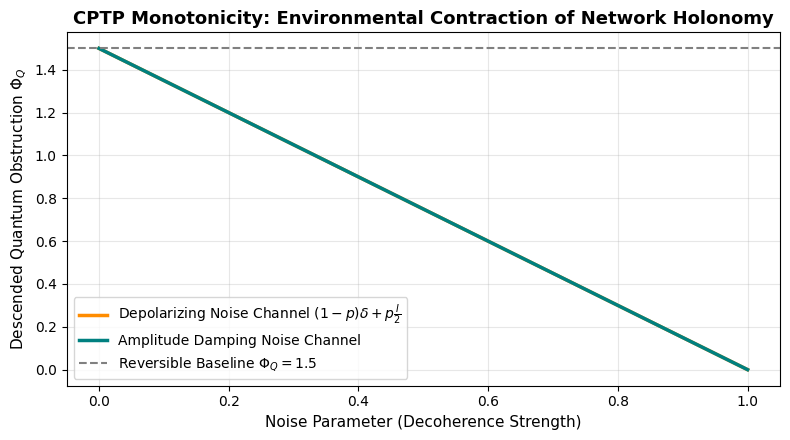

In [5]:
demo4 = demo_cptp_quotient_monotonicity()
print(f"Baseline Quantum Obstruction Phi_Q: {demo4['phi_base']:.4f}")
print(f"Depolarizing Noise (p=0.4):          Phi_Q' = {demo4['depolarizing']['phi_depol']:.4f} (Monotone: {demo4['depolarizing']['is_monotone']})")
print(f"Amplitude Damping (gamma=0.3):       Phi_Q' = {demo4['amplitude_damping']['phi_ad']:.4f} (Monotone: {demo4['amplitude_damping']['is_monotone']})")
print(f"Unitary Rotation (Hadamard):         Phi_Q' = {demo4['unitary_invariance']['phi_u']:.4f} (Exact Invariant: {demo4['unitary_invariance']['is_exact_invariant']})")

# Parametric scan of CPTP noise contraction
comp = GraphComplex.triangle_complex([1.0, 1.0, 1.0])
solver = QuantumQuotientSolver(comp, tol=1e-4)
a_mat = 0.5 * HermitianOperator.SIGMA_Z
delta = Cochain(np.array([a_mat, a_mat, a_mat], dtype=complex), degree=1)

p_vals = np.linspace(0.0, 1.0, 20)
phi_depol_curve = []
phi_damp_curve = []

for p in p_vals:
    ch_depol = KrausChannel.depolarizing(d=2, p=p)
    m_depol = CochainMorphism.uniform(comp, ch_depol)
    _, _, val_depol = m_depol.verify_quotient_monotonicity(solver, delta)
    phi_depol_curve.append(val_depol)
    
    ch_damp = KrausChannel.amplitude_damping(gamma=p)
    m_damp = CochainMorphism.uniform(comp, ch_damp)
    _, _, val_damp = m_damp.verify_quotient_monotonicity(solver, delta)
    phi_damp_curve.append(val_damp)

plt.figure(figsize=(8, 4.5))
plt.plot(p_vals, phi_depol_curve, 'darkorange', lw=2.5, label=r'Depolarizing Noise Channel $(1-p)\delta + p \frac{I}{2}$')
plt.plot(p_vals, phi_damp_curve, 'teal', lw=2.5, label='Amplitude Damping Noise Channel')
plt.axhline(1.5, color='gray', ls='--', label=r'Reversible Baseline $\Phi_Q = 1.5$')
plt.xlabel('Noise Parameter (Decoherence Strength)', fontsize=11)
plt.ylabel(r'Descended Quantum Obstruction $\Phi_Q$', fontsize=11)
plt.title('CPTP Monotonicity: Environmental Contraction of Network Holonomy', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 6. Interactive Gauge Calibration Sandbox
Explore how arbitrary observer calibration choices $\phi(0), \phi(1), \phi(2) \in \mathbb{R}^2$ affect edge errors.
Try shifting potentials and see how the Euclidean vs Taxicab total cost responds!

In [6]:
def evaluate_triangle_potentials(phi0_x=0.0, phi0_y=0.0, phi1_x=0.0, phi1_y=0.0, phi2_x=0.0, phi2_y=0.0):
    phi0 = np.array([phi0_x, phi0_y])
    phi1 = np.array([phi1_x, phi1_y])
    phi2 = np.array([phi2_x, phi2_y])
    
    # Edges: (0, 1), (1, 2), (2, 0)
    w01 = np.array([1.0, 0.0]) - (phi1 - phi0)
    w12 = np.array([0.0, 1.0]) - (phi2 - phi1)
    w20 = np.array([0.0, 0.0]) - (phi0 - phi2)
    
    l1_cost = np.sum(np.abs(w01)) + np.sum(np.abs(w12)) + np.sum(np.abs(w20))
    l2_cost = float(np.linalg.norm(w01) + np.linalg.norm(w12) + np.linalg.norm(w20))
    
    print(f"Chosen Potentials:")
    print(f"  phi(0) = {phi0}, phi(1) = {phi1}, phi(2) = {phi2}")
    print(f"Residual Edge Errors:")
    print(f"  e(0->1) = {w01}")
    print(f"  e(1->2) = {w12}")
    print(f"  e(2->0) = {w20}")
    print(f"Total Costs:")
    print(f"  Taxicab l1 Total Error:  {l1_cost:.4f}  (Global Minimum: 2.0000)")
    print(f"  Euclidean l2 Total Error: {l2_cost:.4f}  (Global Minimum: {np.sqrt(2):.4f})")

# Demonstration run with symmetric zero potentials
evaluate_triangle_potentials(0.0, 0.0, 0.0, 0.0, 0.0, 0.0)

# If ipywidgets is available in an interactive notebook UI:
try:
    import ipywidgets as widgets
    from ipywidgets import interact
    interact(evaluate_triangle_potentials,
             phi0_x=(-1.0, 1.0, 0.1), phi0_y=(-1.0, 1.0, 0.1),
             phi1_x=(-1.0, 1.0, 0.1), phi1_y=(-1.0, 1.0, 0.1),
             phi2_x=(-1.0, 1.0, 0.1), phi2_y=(-1.0, 1.0, 0.1))
except Exception:
    pass

Chosen Potentials:
  phi(0) = [0. 0.], phi(1) = [0. 0.], phi(2) = [0. 0.]
Residual Edge Errors:
  e(0->1) = [1. 0.]
  e(1->2) = [0. 1.]
  e(2->0) = [0. 0.]
Total Costs:
  Taxicab l1 Total Error:  2.0000  (Global Minimum: 2.0000)
  Euclidean l2 Total Error: 2.0000  (Global Minimum: 1.4142)


interactive(children=(FloatSlider(value=0.0, description='phi0_x', max=1.0, min=-1.0), FloatSlider(value=0.0, …

## 7. Summary & Navigation

| Concept | Mathematical Setting | Geometric Behavior | Key Paper Result |
| :--- | :--- | :--- | :--- |
| **1-Cycle Holonomy** | $C^1 / \operatorname{im}(d_0)$ | Circulation $c = \sum_e \delta_e$ cannot be canceled | Non-integrable topological defect |
| **Vector Separation** | $(\mathbb{R}^2, \ell^1)$ vs $(\mathbb{R}^2, \ell^2)$ | Diamond vs Circle | $\Phi_{1,1} / \Phi_{2,1} = \sqrt{2}$ |
| **Qubit Trace Ball** | $\mathcal{H}_2^0, j_Q(X)$ | Smooth 3-ball (Bloch sphere) | Strictly isometric to Euclidean $\ell^2$ |
| **Qutrit Trace Ball** | $\mathcal{H}_3^0, j_Q(X)$ | Spectral cross-polytope with facets | Parallelogram law fails ($16 \ne 20$) |
| **CPTP Monotonicity** | Kraus channels $\mathcal{E}$ | Contraction under noise | $\Phi_Q'([\Lambda^1 \delta]) \le \Phi_Q([\delta])$ |

For full mathematical proofs, cochain boundary operator adjoints, Fenchel dual formulations, and Lean 4 formalization tables, proceed to **`02_rigorous_observer_cochains.ipynb`**.